# LAB 1: Data Pre-processing and Exploratory Data Analysis (EDA)

## Problem Statement
Given a raw, uncurated dataset of retail customers (`CustomerID, Age, Annual_Income_k, City`) the objectives are to:
1. **Identify and rectify structural flaws** - detect missing values in numerical and categorical columns and impute them (median / mode) without introducing bias.
2. **Mitigate anomaly variance** - detect extreme incomes with the **IQR method** and cap them.
3. **Feature engineering** - encode `City` as integers and normalise `Age` and income.
4. **EDA** - histograms, boxplots and a correlation heatmap.

## 1. Objectives
- Understand data cleaning, pre-processing and EDA.
- Handle missing values, outliers and categorical encoding.
- Visualise distributions and correlations with Pandas, Matplotlib and Seaborn.

## 2. Software & Libraries
`numpy`, `pandas`, `matplotlib.pyplot`, `seaborn`, `sklearn.preprocessing`

## 3. Implementation
### Step 1: Loading the dataset (raw data from the lab manual)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler

sns.set_theme(style="whitegrid")

raw = pd.DataFrame({
    "CustomerID":      [101, 102, 103, 104, 105, 106, 107],
    "Age":             [23.0, 45.0, np.nan, 31.0, 22.0, 54.0, 38.0],
    "Annual_Income_k": [50.0, 85.0, 62.0, np.nan, 45.0, 120.0, 350.0],
    "City":            ["New York", "Paris", "New York", "London", np.nan, "London", "Paris"],
})
print("RAW DATASET")
display(raw)

RAW DATASET


,CustomerID,Age,Annual_Income_k,City
0,101,23.0,50.0,New York
1,102,45.0,85.0,Paris
2,103,NaN,62.0,New York
3,104,31.0,NaN,London
4,105,22.0,45.0,NaN
5,106,54.0,120.0,London
6,107,38.0,350.0,Paris


The 7-row table is too small for meaningful plots, so the same cleaning pipeline is written as a **function** and
applied twice: first to the raw table above, then to a larger 200-row synthetic dataset with the same structure
(random gaps and a few extreme incomes) that is used for the EDA charts.

### Step 2: Data inspection & handling missing values

In [2]:
print("Data types / non-null counts:")
raw.info()
print("\nMissing values per column:")
print(raw.isnull().sum())

Data types / non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       7 non-null      int64  
 1   Age              6 non-null      float64
 2   Annual_Income_k  6 non-null      float64
 3   City             6 non-null      str    
dtypes: float64(2), int64(1), str(1)
memory usage: 395.0 bytes

Missing values per column:
CustomerID         0
Age                1
Annual_Income_k    1
City               1
dtype: int64


In [3]:
def impute(frame):
    frame = frame.copy()
    for col in ["Age", "Annual_Income_k"]:          # numerical -> median
        frame[col] = frame[col].fillna(frame[col].median())
    frame["City"] = frame["City"].fillna(frame["City"].mode()[0])   # categorical -> mode
    return frame

raw_imp = impute(raw)
print("After imputation (Age/Income = median, City = mode):")
display(raw_imp)
print("Remaining missing values:", int(raw_imp.isnull().sum().sum()))

After imputation (Age/Income = median, City = mode):


,CustomerID,Age,Annual_Income_k,City
0,101,23.0,50.0,New York
1,102,45.0,85.0,Paris
2,103,34.5,62.0,New York
3,104,31.0,73.5,London
4,105,22.0,45.0,London
5,106,54.0,120.0,London
6,107,38.0,350.0,Paris


Remaining missing values: 0


### Step 3: Outlier detection & treatment (IQR capping)

In [4]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1, q3, iqr, q1 - 1.5 * iqr, q3 + 1.5 * iqr

def cap_outliers(frame, col):
    frame = frame.copy()
    q1, q3, iqr, lo, hi = iqr_bounds(frame[col])
    n_out = int(((frame[col] < lo) | (frame[col] > hi)).sum())
    frame[col + "_capped"] = frame[col].clip(lo, hi)
    print(f"{col}: Q1={q1:.2f}  Q3={q3:.2f}  IQR={iqr:.2f}  bounds=[{lo:.2f}, {hi:.2f}]  outliers={n_out}")
    return frame

raw_cap = cap_outliers(raw_imp, "Annual_Income_k")
display(raw_cap)

Annual_Income_k: Q1=56.00  Q3=102.50  IQR=46.50  bounds=[-13.75, 172.25]  outliers=1


,CustomerID,Age,Annual_Income_k,City,Annual_Income_k_capped
0,101,23.0,50.0,New York,50.00
1,102,45.0,85.0,Paris,85.00
2,103,34.5,62.0,New York,62.00
3,104,31.0,73.5,London,73.50
4,105,22.0,45.0,London,45.00
5,106,54.0,120.0,London,120.00
6,107,38.0,350.0,Paris,172.25


### Step 4: Categorical encoding & feature scaling

In [5]:
def encode_scale(frame):
    frame = frame.copy()
    le = LabelEncoder()
    frame["City_Encoded"] = le.fit_transform(frame["City"])
    print("City encoding:", {c: int(i) for i, c in enumerate(le.classes_)})
    sc = StandardScaler()
    frame[["Age_Scaled", "Income_Scaled"]] = sc.fit_transform(frame[["Age", "Annual_Income_k_capped"]])
    return frame

raw_final = encode_scale(raw_cap)
display(raw_final)

City encoding: {'London': 0, 'New York': 1, 'Paris': 2}


,CustomerID,Age,Annual_Income_k,City,Annual_Income_k_capped,City_Encoded,Age_Scaled,Income_Scaled
0,101,23.0,50.0,New York,50.00,1,-1.157094,-0.878389
1,102,45.0,85.0,Paris,85.00,2,0.902934,-0.043451
2,103,34.5,62.0,New York,62.00,1,-0.080261,-0.592124
3,104,31.0,73.5,London,73.50,0,-0.407993,-0.317788
4,105,22.0,45.0,London,45.00,0,-1.250731,-0.997665
5,106,54.0,120.0,London,120.00,0,1.745673,0.791487
6,107,38.0,350.0,Paris,172.25,2,0.247471,2.037930


### Step 5: Exploratory Data Analysis on a 200-row dataset
The same pipeline is run on a larger dataset so that histograms, boxplots and the heatmap are meaningful.

In [6]:
rng = np.random.default_rng(42)
n = 200
big = pd.DataFrame({
    "CustomerID": np.arange(101, 101 + n),
    "Age": rng.integers(18, 65, n).astype(float),
    "Annual_Income_k": np.round(rng.normal(70, 22, n).clip(20, 140), 1),
    "City": rng.choice(["New York", "Paris", "London", "Tokyo"], n),
})
# a few extreme incomes + random missing values
big.loc[rng.choice(n, 6, replace=False), "Annual_Income_k"] = rng.uniform(300, 450, 6).round(1)
big.loc[rng.choice(n, 20, replace=False), "Age"] = np.nan
big.loc[rng.choice(n, 20, replace=False), "Annual_Income_k"] = np.nan
big.loc[rng.choice(n, 15, replace=False), "City"] = np.nan

print("Missing values before cleaning:\n", big.isnull().sum(), sep="")
df = encode_scale(cap_outliers(impute(big), "Annual_Income_k"))
print("\nMissing values after cleaning:", int(df[["Age", "Annual_Income_k", "City"]].isnull().sum().sum()))
display(df.describe().round(2))

Missing values before cleaning:
CustomerID          0
Age                20
Annual_Income_k    20
City               15
dtype: int64
Annual_Income_k: Q1=55.38  Q3=79.17  IQR=23.80  bounds=[19.68, 114.88]  outliers=11
City encoding: {'London': 0, 'New York': 1, 'Paris': 2, 'Tokyo': 3}

Missing values after cleaning: 0


,CustomerID,Age,Annual_Income_k,Annual_Income_k_capped,City_Encoded,Age_Scaled,Income_Scaled
count,200.00,200.00,200.00,200.00,200.00,200.00,200.00
mean,200.50,41.36,75.58,69.42,1.34,0.00,0.00
std,57.88,12.16,49.24,21.49,1.19,1.00,1.00
min,101.00,18.00,20.00,20.00,0.00,-1.93,-2.31
25%,150.75,32.75,55.38,55.38,0.00,-0.71,-0.66
50%,200.50,41.00,67.15,67.15,1.00,-0.03,-0.11
75%,250.25,51.00,79.18,79.18,2.00,0.79,0.46
max,300.00,64.00,399.90,114.88,3.00,1.87,2.12


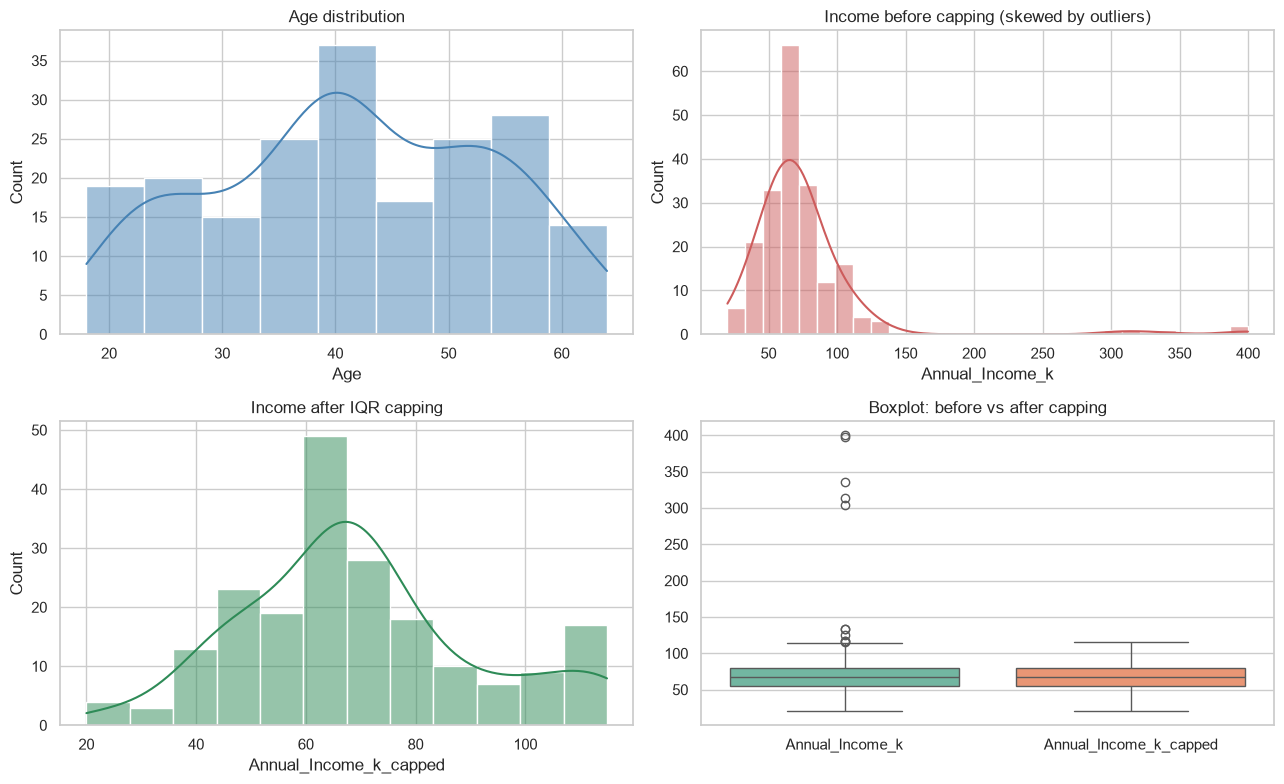

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(df["Age"], kde=True, ax=axes[0, 0], color="steelblue");                axes[0, 0].set_title("Age distribution")
sns.histplot(df["Annual_Income_k"], kde=True, ax=axes[0, 1], color="indianred");     axes[0, 1].set_title("Income before capping (skewed by outliers)")
sns.histplot(df["Annual_Income_k_capped"], kde=True, ax=axes[1, 0], color="seagreen"); axes[1, 0].set_title("Income after IQR capping")
sns.boxplot(data=df[["Annual_Income_k", "Annual_Income_k_capped"]], ax=axes[1, 1], palette="Set2"); axes[1, 1].set_title("Boxplot: before vs after capping")
plt.tight_layout(); plt.show()

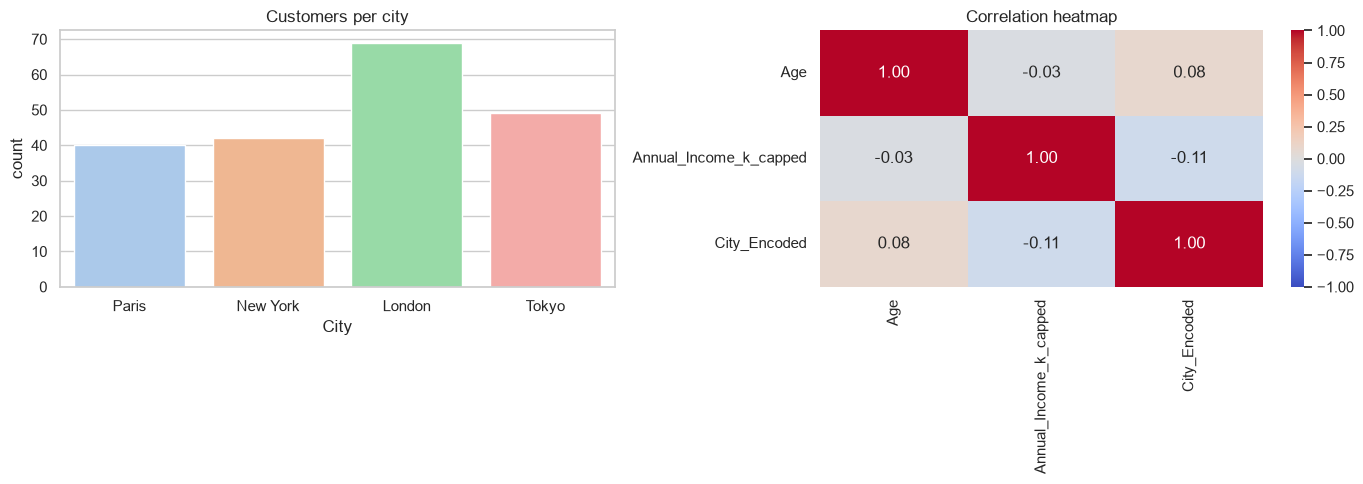

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="City", hue="City", palette="pastel", legend=False, ax=axes[0]); axes[0].set_title("Customers per city")
corr = df[["Age", "Annual_Income_k_capped", "City_Encoded"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[1]); axes[1].set_title("Correlation heatmap")
plt.tight_layout(); plt.show()

## 4. Observations & Summary Table
| Phase | Action Taken | Purpose / Result |
|---|---|---|
| Inspection | `df.info()`, `isnull().sum()` | Identified missing records and mismatched data types. |
| Imputation | Median for numerical, Mode for categorical | Filled gaps without introducing heavy bias. |
| Outlier handling | IQR capping | Removed extreme variance in skewed features (income). |
| Encoding | `LabelEncoder` | Converted textual classes into model-ready integers. |
| Scaling | `StandardScaler` | Put Age and Income on a comparable (mean 0, std 1) scale. |
| EDA | Histograms, boxplots, heatmap | Identified distributions and feature correlations. |

## 5. Conclusion
- **Data cleaning** removed all missing values and tamed the extreme income values (e.g. 350k in the raw table), preventing downstream errors and distorted models.
- **EDA** showed the effect of capping on the income distribution and that the features are only weakly correlated in this dataset; a heatmap is the quickest way to spot strongly correlated pairs before modelling.
- The dataset is now clean, encoded and standardised and ready for machine-learning algorithms.